разница между средним по выборке и мат ожиданием = 1.3130000000001019


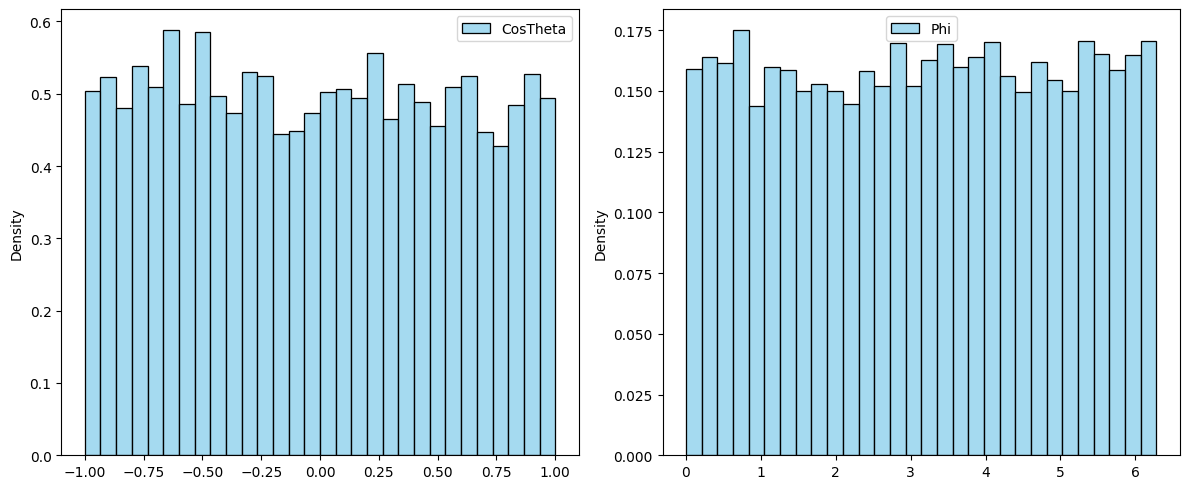

In [46]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

class Source():
    def __init__(self, E:float,origin:np.ndarray,Y=1e4):
        self.Y=Y
        self.N=np.random.poisson(E*Y) 
        self.origin=origin
    def photon_generator(self, bunch=100):
        left = self.N
        while left > 0:
            n = min(bunch, left)
            phi = np.random.uniform(0, 2 * np.pi, n)
            cosTheta = np.random.uniform(-1, 1, n)
            sinTheta = np.sqrt(1 - cosTheta * cosTheta)
            yield np.array([sinTheta * np.cos(phi),sinTheta * np.sin(phi),cosTheta]) 
            left -= n
    def distance_traversed(self,PhotonArray:np.ndarray,R:float):
        t=-self.origin@PhotonArray+np.sqrt(R**2-np.sum(self.origin**2)+(self.origin@PhotonArray)*(self.origin@PhotonArray))
        return t

origin=np.array([0,0,0])
S1=Source(1,origin)

def test_AvgN(N=1000):
    ee=1
    N_exp=ee*10**4
    avg=[]
    for i in range(N):
        S=Source(1,origin)
        avg.append(S.N)
    avg=np.array(avg)
    print(f'разница между средним по выборке и мат ожиданием = {abs(avg.mean()-N_exp)}')

test_AvgN()


def test_IsUniform():
    # np.sum(PhotonArray,axis=1)/S1.N #стремится к нулю при N->inf
    x, y, z = next(S1.photon_generator(S1.N))
    CosTheta = z
    Phi = np.arctan2(y, x)   
    Phi = (Phi + 2*np.pi) % (2*np.pi)
    fig, axes = plt.subplots(1, 2, figsize=(12, 5))    
    sns.histplot(CosTheta, bins=30, stat='density', kde=False, color='skyblue', edgecolor='black',label='CosTheta',ax=axes[0])
    sns.histplot(Phi, bins=30, stat='density', kde=False, color='skyblue', edgecolor='black',label='Phi',ax=axes[1])
    axes[0].legend()
    axes[1].legend()
    plt.tight_layout()
    plt.show()

test_IsUniform()